# Week 2 Homework — Diffusion Models: Schedules, Conditioning, and Latency

Dataset: FashionMNIST

In [1]:
!pip install pytorch-fid --quiet

In [2]:
import os, re, time, subprocess
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from torch.utils.data import DataLoader

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)
os.makedirs("images", exist_ok=True)

Device: cuda


## Part 1 — Diffusion on FashionMNIST with Schedule Comparison

In [3]:
# Data: FashionMNIST, pixels scaled to [-1, 1]
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
loader = DataLoader(train_data, batch_size=128, shuffle=True, drop_last=True)
T = 1000

# Noise schedules
def linear_schedule(T=1000, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, T)

def cosine_schedule(T=1000, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float32)
    f = torch.cos(((steps / T + s) / (1 + s)) * torch.pi / 2) ** 2
    alphas_bar = f / f[0]
    betas = 1 - (alphas_bar[1:] / alphas_bar[:-1])
    return torch.clamp(betas, 0, 0.999)

# Closed-form forward process
def q_sample(x0, t, betas, noise=None):
    alpha_bars = torch.cumprod(1 - betas.to(x0.device), dim=0)
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    if noise is None:
        noise = torch.randn_like(x0)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 170kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.3MB/s]


In [4]:
# U-Net
class SinusoidalTimeEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-torch.arange(half, device=t.device) * (torch.log(torch.tensor(10000.0)) / (half - 1)))
        args = t[:, None].float() * freqs[None]
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.time_mlp = nn.Linear(time_dim, ch)
        self.norm1 = nn.GroupNorm(8, ch)
        self.norm2 = nn.GroupNorm(8, ch)
    def forward(self, x, t_emb):
        h = self.norm1(x)
        h = torch.relu(self.conv1(h))
        h = h + self.time_mlp(t_emb)[:, :, None, None]
        h = self.norm2(h)
        return x + self.conv2(torch.relu(h))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.reduce = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.merge = nn.Conv2d(out_ch * 2, out_ch, 1)
        self.res = ResBlock(out_ch, time_dim)
    def forward(self, x, skip, t_emb):
        x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        x = self.reduce(x)
        x = self.merge(torch.cat([x, skip], dim=1))
        return self.res(x, t_emb)

class UNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_emb = nn.Sequential(SinusoidalTimeEmb(time_dim), nn.Linear(time_dim, time_dim), nn.ReLU())
        self.inp = nn.Conv2d(1, 32, 3, padding=1)
        self.enc1, self.down1 = ResBlock(32, time_dim), nn.Conv2d(32, 64, 3, stride=2, padding=1)
        self.enc2, self.down2 = ResBlock(64, time_dim), nn.Conv2d(64, 128, 3, stride=2, padding=1)
        self.enc3, self.down3 = ResBlock(128, time_dim), nn.Conv2d(128, 128, 3, stride=2, padding=1)
        self.mid = ResBlock(128, time_dim)
        self.up3 = Up(128, 128, time_dim)
        self.up2 = Up(128, 64, time_dim)
        self.up1 = Up(64, 32, time_dim)
        self.out = nn.Conv2d(32, 1, 3, padding=1)

    def forward(self, x, t, cond_emb=None):
        t_emb = self.time_emb(t)
        if cond_emb is not None:
            t_emb = t_emb + cond_emb
        x = self.inp(x)
        s1 = self.enc1(x, t_emb); x = self.down1(s1)
        s2 = self.enc2(x, t_emb); x = self.down2(s2)
        s3 = self.enc3(x, t_emb); x = self.down3(s3)
        x = self.mid(x, t_emb)
        x = self.up3(x, s3, t_emb)
        x = self.up2(x, s2, t_emb)
        x = self.up1(x, s1, t_emb)
        return self.out(x)

In [5]:
# DDPM sampler
@torch.no_grad()
def ddpm_sample(model, betas, T=1000, shape=(1, 1, 28, 28)):
    betas = betas.to(DEVICE)
    alphas = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    x = torch.randn(shape, device=DEVICE)
    for t in reversed(range(T)):
        eps_pred = model(x, torch.full((shape[0],), t, device=DEVICE))
        coef1 = betas[t] / (1 - alpha_bars[t]).sqrt()
        x = (x - coef1 * eps_pred) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn_like(x)
    return x

def to01(x):
    return ((x + 1) / 2).clamp(0, 1).cpu()

def save_grid(x, path, title):
    g = make_grid(to01(x), nrow=5, padding=2)
    save_image(g, path)
    plt.figure(figsize=(4, 4)); plt.imshow(g.permute(1, 2, 0)); plt.title(title); plt.axis("off"); plt.show()

# FID helpers: 1000 generated vs 1000 real images
def save_imgs(x, folder):
    os.makedirs(folder, exist_ok=True)
    for i, img in enumerate(x):
        save_image(img, f"{folder}/{i:04d}.png")

save_imgs(torch.stack([(train_data[i][0] + 1) / 2 for i in range(1000)]), "fid/real")

def fid(path_a, path_b):
    out = subprocess.run(["python", "-m", "pytorch_fid", path_a, path_b, "--device", DEVICE],
                         capture_output=True, text=True)
    m = re.search(r"FID:\s+([\d.]+)", out.stdout)
    if not m:
        print(out.stderr[-600:])
    return float(m.group(1)) if m else None

In [6]:
def run_variant(name, betas, epochs=40):
    """Train one schedule variant. 5x5 grids at epochs 10/20/30/40, FID at epochs 20 and 40."""
    betas = betas.to(DEVICE)
    torch.manual_seed(0)
    model = UNet().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    train_time, fids = 0.0, {}
    for epoch in range(1, epochs + 1):
        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        model.train()
        total = 0.0
        for x, _ in loader:
            x = x.to(DEVICE)
            t = torch.randint(0, T, (x.size(0),), device=DEVICE)
            x_t, eps = q_sample(x, t, betas)
            loss = F.mse_loss(model(x_t, t), eps)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        if DEVICE == "cuda": torch.cuda.synchronize()
        train_time += time.time() - t0            # sampling / FID time is not counted
        print(f"[{name}] epoch {epoch}/{epochs}: loss = {total / len(loader):.4f}")

        if epoch in (10, 20, 30, 40):
            model.eval()
            samples = ddpm_sample(model, betas, shape=(25, 1, 28, 28))
            save_grid(samples, f"images/p1_{name}_epoch{epoch}.png", f"Variant {name} - epoch {epoch}")
            if epoch in (20, 40):
                gen = torch.cat([ddpm_sample(model, betas, shape=(500, 1, 28, 28)) for _ in range(2)])
                save_imgs(to01(gen), f"fid/{name}_epoch{epoch}")
                fids[epoch] = fid("fid/real", f"fid/{name}_epoch{epoch}")
                print(f"[{name}] FID at epoch {epoch}: {fids[epoch]}")
    return train_time, fids

results = {}

[A] epoch 1/40: loss = 0.0908
[A] epoch 2/40: loss = 0.0529
[A] epoch 3/40: loss = 0.0487
[A] epoch 4/40: loss = 0.0453
[A] epoch 5/40: loss = 0.0438
[A] epoch 6/40: loss = 0.0428
[A] epoch 7/40: loss = 0.0438
[A] epoch 8/40: loss = 0.0425
[A] epoch 9/40: loss = 0.0420
[A] epoch 10/40: loss = 0.0413


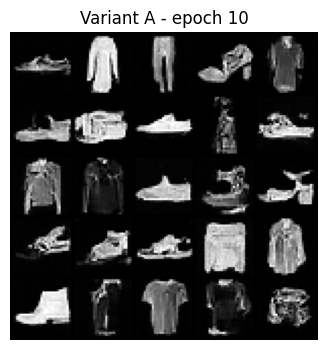

[A] epoch 11/40: loss = 0.0416
[A] epoch 12/40: loss = 0.0409
[A] epoch 13/40: loss = 0.0406
[A] epoch 14/40: loss = 0.0408
[A] epoch 15/40: loss = 0.0402
[A] epoch 16/40: loss = 0.0397
[A] epoch 17/40: loss = 0.0396
[A] epoch 18/40: loss = 0.0395
[A] epoch 19/40: loss = 0.0403
[A] epoch 20/40: loss = 0.0394


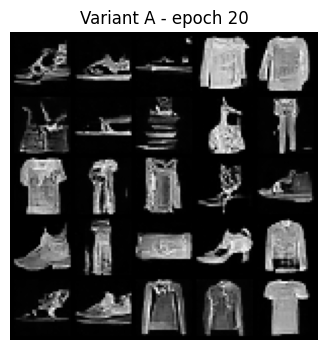

[A] FID at epoch 20: 47.18203040935629
[A] epoch 21/40: loss = 0.0395
[A] epoch 22/40: loss = 0.0389
[A] epoch 23/40: loss = 0.0393
[A] epoch 24/40: loss = 0.0394
[A] epoch 25/40: loss = 0.0387
[A] epoch 26/40: loss = 0.0386
[A] epoch 27/40: loss = 0.0390
[A] epoch 28/40: loss = 0.0388
[A] epoch 29/40: loss = 0.0386
[A] epoch 30/40: loss = 0.0385


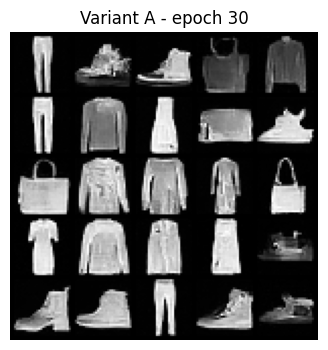

[A] epoch 31/40: loss = 0.0383
[A] epoch 32/40: loss = 0.0384
[A] epoch 33/40: loss = 0.0384
[A] epoch 34/40: loss = 0.0383
[A] epoch 35/40: loss = 0.0381
[A] epoch 36/40: loss = 0.0380
[A] epoch 37/40: loss = 0.0379
[A] epoch 38/40: loss = 0.0380
[A] epoch 39/40: loss = 0.0380
[A] epoch 40/40: loss = 0.0377


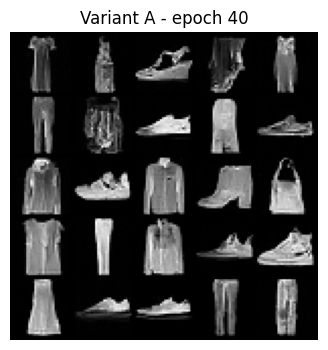

[A] FID at epoch 40: 41.9637771366983


In [8]:
# Variant A: linear schedule
results["A"] = run_variant("A", linear_schedule(T, 1e-4, 0.02))

[B] epoch 1/40: loss = 0.1413
[B] epoch 2/40: loss = 0.0912
[B] epoch 3/40: loss = 0.0847
[B] epoch 4/40: loss = 0.0803
[B] epoch 5/40: loss = 0.0783
[B] epoch 6/40: loss = 0.0766
[B] epoch 7/40: loss = 0.0775
[B] epoch 8/40: loss = 0.0757
[B] epoch 9/40: loss = 0.0750
[B] epoch 10/40: loss = 0.0740


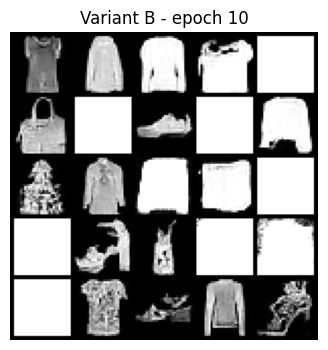

[B] epoch 11/40: loss = 0.0743
[B] epoch 12/40: loss = 0.0733
[B] epoch 13/40: loss = 0.0728
[B] epoch 14/40: loss = 0.0729
[B] epoch 15/40: loss = 0.0721
[B] epoch 16/40: loss = 0.0715
[B] epoch 17/40: loss = 0.0712
[B] epoch 18/40: loss = 0.0712
[B] epoch 19/40: loss = 0.0720
[B] epoch 20/40: loss = 0.0710


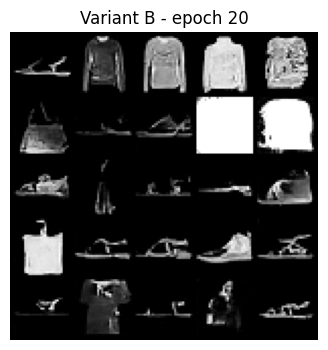

[B] FID at epoch 20: 90.82556326631615
[B] epoch 21/40: loss = 0.0710
[B] epoch 22/40: loss = 0.0705
[B] epoch 23/40: loss = 0.0706
[B] epoch 24/40: loss = 0.0710
[B] epoch 25/40: loss = 0.0697
[B] epoch 26/40: loss = 0.0696
[B] epoch 27/40: loss = 0.0701
[B] epoch 28/40: loss = 0.0699
[B] epoch 29/40: loss = 0.0694
[B] epoch 30/40: loss = 0.0694


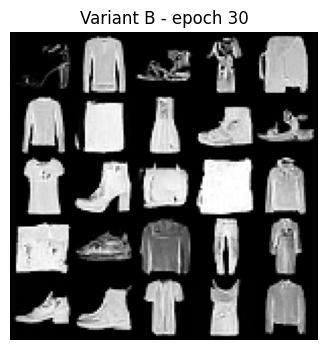

[B] epoch 31/40: loss = 0.0691
[B] epoch 32/40: loss = 0.0695
[B] epoch 33/40: loss = 0.0693
[B] epoch 34/40: loss = 0.0694
[B] epoch 35/40: loss = 0.0690
[B] epoch 36/40: loss = 0.0689
[B] epoch 37/40: loss = 0.0684
[B] epoch 38/40: loss = 0.0688
[B] epoch 39/40: loss = 0.0686
[B] epoch 40/40: loss = 0.0683


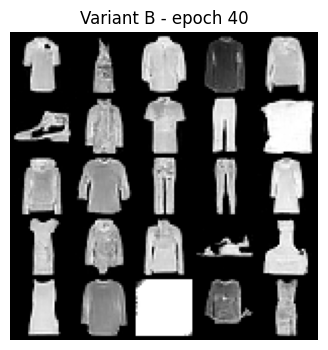

[B] FID at epoch 40: 36.25956127829636


In [9]:
# Variant B: cosine schedule
results["B"] = run_variant("B", cosine_schedule(T, s=0.008))

[C] epoch 1/40: loss = 0.1292
[C] epoch 2/40: loss = 0.0815
[C] epoch 3/40: loss = 0.0761
[C] epoch 4/40: loss = 0.0720
[C] epoch 5/40: loss = 0.0702
[C] epoch 6/40: loss = 0.0685
[C] epoch 7/40: loss = 0.0694
[C] epoch 8/40: loss = 0.0677
[C] epoch 9/40: loss = 0.0671
[C] epoch 10/40: loss = 0.0663


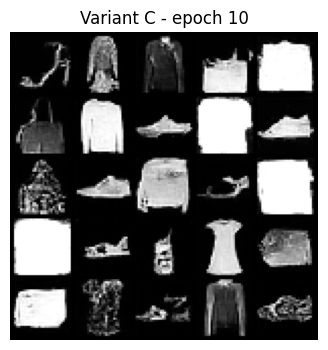

[C] epoch 11/40: loss = 0.0666
[C] epoch 12/40: loss = 0.0657
[C] epoch 13/40: loss = 0.0653
[C] epoch 14/40: loss = 0.0654
[C] epoch 15/40: loss = 0.0647
[C] epoch 16/40: loss = 0.0642
[C] epoch 17/40: loss = 0.0639
[C] epoch 18/40: loss = 0.0639
[C] epoch 19/40: loss = 0.0645
[C] epoch 20/40: loss = 0.0636


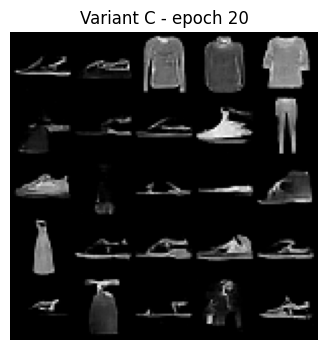

[C] FID at epoch 20: 86.11436859318229
[C] epoch 21/40: loss = 0.0636
[C] epoch 22/40: loss = 0.0632
[C] epoch 23/40: loss = 0.0633
[C] epoch 24/40: loss = 0.0636
[C] epoch 25/40: loss = 0.0625
[C] epoch 26/40: loss = 0.0623
[C] epoch 27/40: loss = 0.0628
[C] epoch 28/40: loss = 0.0626
[C] epoch 29/40: loss = 0.0623
[C] epoch 30/40: loss = 0.0622


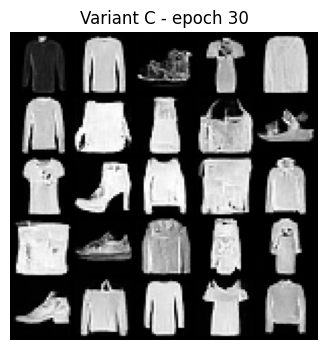

[C] epoch 31/40: loss = 0.0620
[C] epoch 32/40: loss = 0.0622
[C] epoch 33/40: loss = 0.0621
[C] epoch 34/40: loss = 0.0621
[C] epoch 35/40: loss = 0.0619
[C] epoch 36/40: loss = 0.0617
[C] epoch 37/40: loss = 0.0613
[C] epoch 38/40: loss = 0.0616
[C] epoch 39/40: loss = 0.0614
[C] epoch 40/40: loss = 0.0612


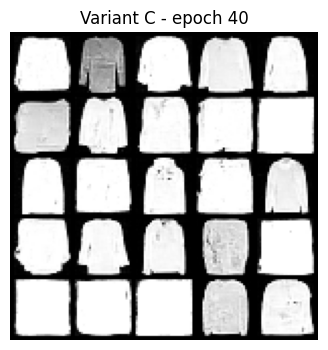

[C] FID at epoch 40: 149.72991842869925


In [10]:
# Variant C: modified cosine schedule
results["C"] = run_variant("C", cosine_schedule(T, s=0.04))

In [11]:
names = {"A": "A - Linear", "B": "B - Cosine (s=0.008)", "C": "C - Cosine (s=0.04)"}
table = pd.DataFrame([{
    "Variant": names[k],
    "Epoch 20 FID": results[k][1].get(20),
    "Epoch 40 FID": results[k][1].get(40),
    "Training time": f"{results[k][0] / 60:.1f} min",
} for k in ["A", "B", "C"]])
print(table.to_string(index=False))

             Variant  Epoch 20 FID  Epoch 40 FID Training time
          A - Linear     47.182030     41.963777      23.2 min
B - Cosine (s=0.008)     90.825563     36.259561      23.2 min
 C - Cosine (s=0.04)     86.114369    149.729918      23.2 min


Analysis

Which schedule performed best on FashionMNIST and does it match your Week 2 MNIST results? What changes between MNIST and FashionMNIST make the schedule choice matter more?

Answer:

At epoch 40, Variant B gave the best results with an FID score of 36.3. It performed better than linear which scored 42.0 and the modified cosine which scored 149.7. This was similar to my MNIST results where cosine also performed better than linear. However, at epoch 20 the linear schedule was better so cosine needed more training time to improve. Variant C actually got worse between epochs 20 and 40 which could mean its training was unstable. The FashionMNIST dataset is more complicated than MNIST because clothing items have different shapes, textures and shades of grey.

## Part 2 — Class-Conditional Diffusion

In [12]:
NULL = 10   # extra class index meaning "no class"

class CondUNet(UNet):
    """Same U-Net; the class label is embedded to the time-embedding size and added to it."""
    def __init__(self, time_dim=128, num_classes=10):
        super().__init__(time_dim)
        self.class_emb = nn.Embedding(num_classes + 1, time_dim)
    def forward(self, x, t, y):
        return super().forward(x, t, cond_emb=self.class_emb(y))

betas_c = cosine_schedule(T).to(DEVICE)      # cosine schedule
cond_model = CondUNet().to(DEVICE)
optimizer = torch.optim.Adam(cond_model.parameters(), lr=1e-3)

EPOCHS = 40
for epoch in range(1, EPOCHS + 1):
    cond_model.train()
    total = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        drop = torch.rand(y.size(0), device=DEVICE) < 0.15            # 15% unconditional dropout
        y = torch.where(drop, torch.full_like(y, NULL), y)
        t = torch.randint(0, T, (x.size(0),), device=DEVICE)
        x_t, eps = q_sample(x, t, betas_c)
        loss = F.mse_loss(cond_model(x_t, t, y), eps)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
    print(f"Epoch {epoch}/{EPOCHS}: loss = {total / len(loader):.4f}")

Epoch 1/40: loss = 0.1433
Epoch 2/40: loss = 0.0897
Epoch 3/40: loss = 0.0832
Epoch 4/40: loss = 0.0798
Epoch 5/40: loss = 0.0781
Epoch 6/40: loss = 0.0770
Epoch 7/40: loss = 0.0755
Epoch 8/40: loss = 0.0744
Epoch 9/40: loss = 0.0734
Epoch 10/40: loss = 0.0738
Epoch 11/40: loss = 0.0732
Epoch 12/40: loss = 0.0726
Epoch 13/40: loss = 0.0723
Epoch 14/40: loss = 0.0719
Epoch 15/40: loss = 0.0719
Epoch 16/40: loss = 0.0717
Epoch 17/40: loss = 0.0705
Epoch 18/40: loss = 0.0707
Epoch 19/40: loss = 0.0706
Epoch 20/40: loss = 0.0707
Epoch 21/40: loss = 0.0705
Epoch 22/40: loss = 0.0701
Epoch 23/40: loss = 0.0702
Epoch 24/40: loss = 0.0697
Epoch 25/40: loss = 0.0700
Epoch 26/40: loss = 0.0699
Epoch 27/40: loss = 0.0690
Epoch 28/40: loss = 0.0695
Epoch 29/40: loss = 0.0689
Epoch 30/40: loss = 0.0694
Epoch 31/40: loss = 0.0687
Epoch 32/40: loss = 0.0690
Epoch 33/40: loss = 0.0689
Epoch 34/40: loss = 0.0683
Epoch 35/40: loss = 0.0689
Epoch 36/40: loss = 0.0678
Epoch 37/40: loss = 0.0682
Epoch 38/4

In [13]:
# Classifier-free guidance sampling: two model calls per step (with / without the class label)
@torch.no_grad()
def ddpm_sample_cfg(model, betas, labels, w=3.0, T=1000):
    betas = betas.to(DEVICE)
    alphas = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    y = torch.tensor(labels, device=DEVICE)
    y_null = torch.full_like(y, NULL)
    x = torch.randn(len(labels), 1, 28, 28, device=DEVICE)
    for t in reversed(range(T)):
        tt = torch.full((len(labels),), t, device=DEVICE)
        eps_cond = model(x, tt, y)
        eps_uncond = model(x, tt, y_null)
        eps = eps_uncond + w * (eps_cond - eps_uncond)          # w=1 is plain conditional sampling
        coef1 = betas[t] / (1 - alpha_bars[t]).sqrt()
        x = (x - coef1 * eps) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn_like(x)
    return x

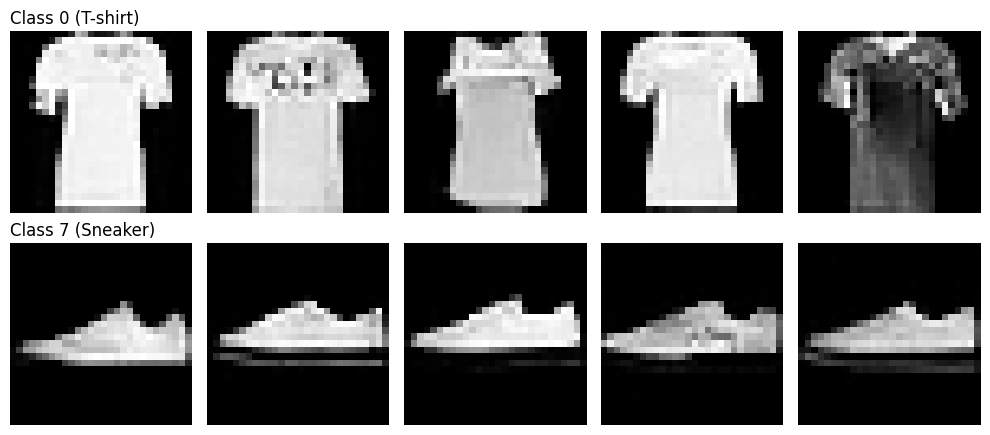

In [14]:
# Demonstration: 5 samples of class 0 (T-shirt) and 5 of class 7 (Sneaker)
cond_model.eval()
torch.manual_seed(0)
demo = ddpm_sample_cfg(cond_model, betas_c, [0] * 5 + [7] * 5, w=3.0)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(to01(demo[i]).squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
axes[0, 0].set_title("Class 0 (T-shirt)", loc="left")
axes[1, 0].set_title("Class 7 (Sneaker)", loc="left")
plt.tight_layout()
plt.savefig("images/p2_demo_w3.png", dpi=150, bbox_inches="tight")
plt.show()

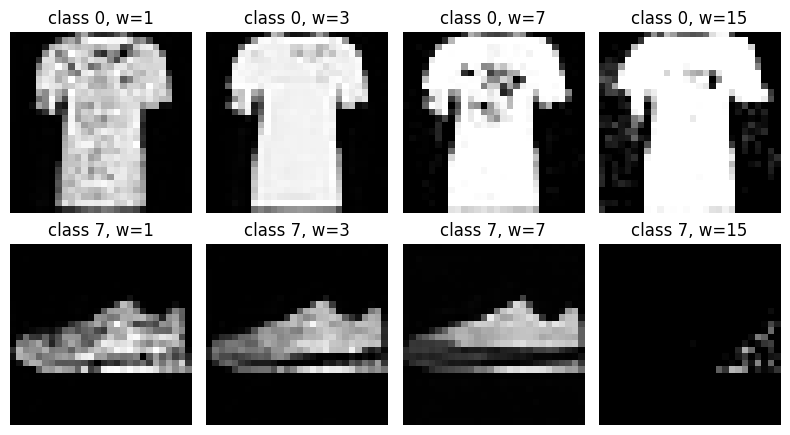

In [15]:
# Guidance scale sweep: w = 1, 3, 7, 15, one row of 4 images per class
ws = [1, 3, 7, 15]
fig, axes = plt.subplots(2, 4, figsize=(8, 4.5))
for r, cls in enumerate([0, 7]):
    for c, w in enumerate(ws):
        torch.manual_seed(0)
        img = ddpm_sample_cfg(cond_model, betas_c, [cls], w=w)
        axes[r, c].imshow(to01(img[0]).squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"class {cls}, w={w}")
        axes[r, c].axis("off")
plt.tight_layout()
plt.savefig("images/p2_guidance_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

Analysis

What happens to diversity and prompt adherence as you increase guidance scale? Where does quality start to degrade and why?

Answer:

At low guidance, the images have more variety but are often blurry and do not clearly match the requested class. As guidance increases, the images become clearer and more recognisable as T-shirts or sneakers. However, there is less variety because the model focuses more on typical examples of each class. At very high guidance the image quality gets worse. The images become too bright and have strange patterns or distorted details. This happens because the model follows the prompt too strongly and pushes the image generation too far so I think a middle guidance value gives the best balance between image quality and variety.